# T25 -- Primary forward-accuracy candidate filtering/ranking, manual check

**Scope.** This notebook is a visualization/inspection artifact only. No scientific
logic is reimplemented -- every filtering/ranking/merging decision below is
computed entirely by `iste.candidate_screening.filter_and_rank_candidates` (T25),
over synthetic `CandidateRecord`s (standing in for real T17-T24 output). No formal
source inference, AIS attribution, or `c_hat*` is computed anywhere here.

**What this demonstrates.** Six synthetic candidates, deliberately built to
exercise every part of T25's contract in one scene:

- **`weak-support-good-forward`** vs. **`strong-support-bad-forward`**: the first
  has WEAK backward KDE support but an EXCELLENT forward match; the second has
  STRONG backward support but a POOR forward match. Forward accuracy alone decides
  the outcome -- the weak-support candidate survives and ranks first, the
  strong-support one is rejected, and backward support never enters the decision.
- **`dup-a`** / **`dup-b`**: two near-duplicate peaks (~70 m apart, same `t_s`).
  `dup-a` has the better forward error and survives; `dup-b` is merged into it
  (never independently ranked).
- **`unvalidated-candidate`**: no valid forcing-member result at all -- rejected
  immediately, with no rank, regardless of its (strong) backward support.
- **`other-time-candidate`**: a different historical timestamp `t_s`, confirming
  multiple historical times remain represented in the final candidate set.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

from iste.candidate_extraction import CoreRegion
from iste.candidate_screening import CandidateRecord, ScreeningConfig, filter_and_rank_candidates

## 1. Six synthetic candidates (standing in for real T17-T24 output)

In [2]:
T_S_1 = np.datetime64("2020-01-01T00:00:00", "ns")
T_S_2 = np.datetime64("2020-01-01T06:00:00", "ns")


def make_record(candidate_id, x_peak, y_peak, t_s, support_score, forward_error, forward_consistency, status="validated"):
    return CandidateRecord(
        candidate_id=candidate_id, x_peak=x_peak, y_peak=y_peak, t_s=t_s,
        support_score=support_score, density_score=support_score * 0.8,
        weighted_support_score=support_score * 0.6, pixel_diversity_score=3.0,
        core_definition=CoreRegion(center_lat=y_peak, center_lon=x_peak, radius_m=5000.0),
        core_particle_count_Y=25, forward_particle_count_N_forward=10, sampling_seed=42,
        forcing_members_validated=(0, 1, 2) if status == "validated" else (),
        forward_error_by_member=({0: forward_error, 1: forward_error, 2: forward_error} if status == "validated" else {}),
        forward_consistency_by_member=({0: forward_consistency, 1: forward_consistency, 2: forward_consistency} if status == "validated" else {}),
        candidate_forward_error=(forward_error if status == "validated" else float("nan")),
        candidate_forward_consistency=(forward_consistency if status == "validated" else float("nan")),
        forward_validation_status=status,
    )

records = [
    make_record("weak-support-good-forward", 100.0, 20.0, T_S_1, support_score=2.0, forward_error=0.10, forward_consistency=0.90),
    make_record("strong-support-bad-forward", 105.0, 22.0, T_S_1, support_score=80.0, forward_error=0.75, forward_consistency=0.25),
    make_record("dup-a", 101.0, 21.0, T_S_1, support_score=15.0, forward_error=0.30, forward_consistency=0.70),
    make_record("dup-b", 101.0006, 21.0006, T_S_1, support_score=10.0, forward_error=0.45, forward_consistency=0.55),  # ~70m from dup-a
    make_record("unvalidated-candidate", 95.0, 18.0, T_S_1, support_score=50.0, forward_error=None, forward_consistency=None, status="unvalidated"),
    make_record("other-time-candidate", 97.0, 24.0, T_S_2, support_score=5.0, forward_error=0.20, forward_consistency=0.80),
]

## 2. T25 filtering/ranking

Threshold mode (`error_threshold=0.5`) plus near-duplicate merging
(`merge_separation_m=1000.0` -- 1 km) applied AFTER filtering, within each `t_s`
group independently.

In [3]:
config = ScreeningConfig(mode="threshold", error_threshold=0.5, merge_separation_m=1000.0)
decisions = filter_and_rank_candidates(records, config)
by_id = {d.record.candidate_id: d for d in decisions}

for cid, d in by_id.items():
    print(f"{cid:28s} accepted={d.accepted!s:5s} rank={d.rank} reason={d.rejection_reason}")

assert by_id["weak-support-good-forward"].accepted and by_id["weak-support-good-forward"].rank == 1
assert not by_id["strong-support-bad-forward"].accepted  # strong support did NOT save it
assert by_id["dup-a"].accepted and not by_id["dup-b"].accepted
assert "merged into near-duplicate candidate 'dup-a'" in by_id["dup-b"].rejection_reason
assert not by_id["unvalidated-candidate"].accepted and by_id["unvalidated-candidate"].rank is None
assert by_id["other-time-candidate"].accepted  # different t_s, preserved independently

unvalidated-candidate        accepted=False rank=None reason=forward-unvalidated (no valid forcing-member result)
strong-support-bad-forward   accepted=False rank=None reason=forward error 0.75 exceeds configured threshold 0.5
dup-b                        accepted=False rank=None reason=merged into near-duplicate candidate 'dup-a' (same t_s, separation < 1000.0 m)
weak-support-good-forward    accepted=True  rank=1 reason=
other-time-candidate         accepted=True  rank=2 reason=
dup-a                        accepted=True  rank=3 reason=


## 3. Visualization

Left: spatial modes before/after screening (accepted = filled circle with final
rank, rejected = X), colored by historical timestamp `t_s`. Right: forward error
(the PRIMARY signal, x-axis) vs. backward support (y-axis, NOT used for the
decision) -- the vertical dashed line is the configured threshold; acceptance
depends only on which side of it a candidate falls, regardless of its support.

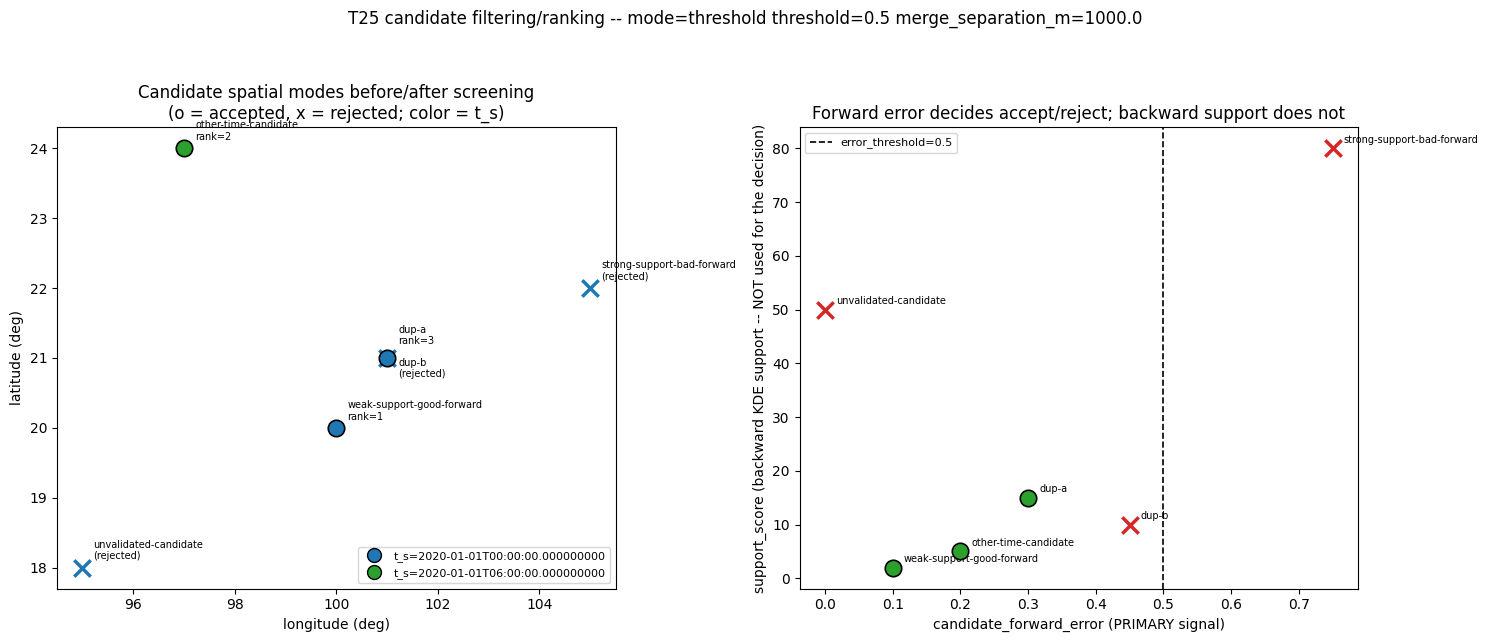

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

ax = axes[0]
t_s_colors = {T_S_1: "tab:blue", T_S_2: "tab:green"}
text_offsets = {"dup-a": (8, 10), "dup-b": (8, -14)}
for cid, d in by_id.items():
    r = d.record
    color = t_s_colors[r.t_s]
    if d.accepted:
        ax.scatter(r.x_peak, r.y_peak, s=140, c=color, marker="o", edgecolors="black", linewidths=1.2, zorder=3)
    else:
        ax.scatter(r.x_peak, r.y_peak, s=140, c=color, marker="x", linewidths=2.5, zorder=3)
    label = f"{cid}\nrank={d.rank}" if d.accepted else f"{cid}\n(rejected)"
    xytext = text_offsets.get(cid, (8, 6))
    ax.annotate(label, (r.x_peak, r.y_peak), textcoords="offset points", xytext=xytext, fontsize=7)
ax.set_xlabel("longitude (deg)")
ax.set_ylabel("latitude (deg)")
ax.set_title("Candidate spatial modes before/after screening\n(o = accepted, x = rejected; color = t_s)")
legend_elems = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=t_s_colors[T_S_1], markeredgecolor="black", markersize=10, label=f"t_s={T_S_1}"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=t_s_colors[T_S_2], markeredgecolor="black", markersize=10, label=f"t_s={T_S_2}"),
]
ax.legend(handles=legend_elems, fontsize=8, loc="lower right")

ax = axes[1]
for cid, d in by_id.items():
    r = d.record
    color = "tab:green" if d.accepted else "tab:red"
    error_val = 0.0 if np.isnan(r.candidate_forward_error) else r.candidate_forward_error
    if d.accepted:
        ax.scatter(error_val, r.support_score, s=140, c=color, marker="o", edgecolors="black", linewidths=1.2, zorder=3)
    else:
        ax.scatter(error_val, r.support_score, s=140, c=color, marker="x", linewidths=2.5, zorder=3)
    ax.annotate(cid, (error_val, r.support_score), textcoords="offset points", xytext=(8, 4), fontsize=7)
ax.axvline(config.error_threshold, color="black", linestyle="--", linewidth=1.2, label=f"error_threshold={config.error_threshold}")
ax.set_xlabel("candidate_forward_error (PRIMARY signal)")
ax.set_ylabel("support_score (backward KDE support -- NOT used for the decision)")
ax.set_title("Forward error decides accept/reject; backward support does not")
ax.legend(fontsize=8)

fig.suptitle(
    f"T25 candidate filtering/ranking -- mode={config.mode} threshold={config.error_threshold} "
    f"merge_separation_m={config.merge_separation_m}",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## Interpretation limits

- This is a **forward-screened candidate set**, not a posterior or a final source
  attribution (`README.md` Sec. 25). No AIS, likelihood, or formal source inference
  is computed here.
- `support_score` (and every other T16/T17 backward-KDE field) is preserved on
  every `CandidateRecord` purely as PROVENANCE ("why was this candidate proposed?")
  -- `filter_and_rank_candidates` never reads it to decide accept/reject or rank
  ("does this candidate reproduce the observed slick well enough to survive?" is
  answered by forward accuracy alone).
- Near-duplicate merging only ever happens among already-accepted survivors, within
  one `t_s` group at a time, using the explicit `merge_separation_m` configured
  here -- it never runs before filtering and never merges across different
  historical timestamps.
- Every rejected candidate's `rejection_reason` is preserved for auditability, and
  every accepted candidate's full provenance (support scores, core definition,
  particle counts, sampling seed, per-member forward results) survives unchanged
  alongside its final rank.